# Parte II — Aprendendo a inverter uma sequência de comprimento fixo

**DAS410116 — Inteligência Artificial Generativa · UFSC · 2026/2**
**Professor:** Eric A. Antonelo
**Aluno:** Leonardo Coli
**Fontes e uso de IA:** Claude.


Aqui a atenção precisa aprender

$$[x_0,x_1,\ldots,x_{L-1}]\longmapsto[x_{L-1},\ldots,x_1,x_0]$$

com comprimento fixo $L=5$. Não há dimensão de batch. A matriz de atenção **não** é alvo de treino: a única supervisão é o erro entre a sequência prevista e a sequência invertida.

## 0. Configuração

In [1]:
import math
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(7)
torch.set_printoptions(precision=3, sci_mode=False)

## 1. Reaproveitando a implementação da Parte I

Mesma conta da Parte I, agora com o escalar positivo `logit_scale` multiplicando os logits já escalados:

$$A=\operatorname{softmax}\!\left(s\,\frac{QK^\top}{\sqrt{d_k}}\right).$$

In [2]:
def compute_attention_weights(Q, K, mask=None, logit_scale=1.0):
    # 1.1: scores = Q K^T / sqrt(d_k), multiplicados por s > 0, máscara opcional, softmax nas keys
    d_k = Q.shape[-1]
    scores = (Q @ K.T) / math.sqrt(d_k)
    scores = logit_scale * scores
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    return torch.softmax(scores, dim=-1)


def scaled_dot_product_attention(Q, K, V, mask=None, logit_scale=1.0):
    # 1.2: A e depois A @ V
    A = compute_attention_weights(Q, K, mask=mask, logit_scale=logit_scale)
    return A @ V, A

## 2. Posições one-hot — 0,30 ponto

Com $L$ fixo, $P=I_L$: cada linha identifica uma posição absoluta.

In [3]:
L = 5
positions = torch.eye(L)

print("positions =")
print(positions)
print("shape:", positions.shape)

positions =
tensor([[1., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0.],
        [0., 0., 1., 0., 0.],
        [0., 0., 0., 1., 0.],
        [0., 0., 0., 0., 1.]])
shape: torch.Size([5, 5])


### Resposta escrita 2

**Pergunta.** Por que a dimensão de posição é igual a `L`? Por que isso impede aplicar as mesmas matrizes de projeção
a outro comprimento?

**Resposta**

Com one-hot, cada posição é um vetor da base canônica de $\mathbb R^L$. Para ter $L$ posições distintas e ortogonais
são necessárias $L$ coordenadas, por isso $P=I_L$ tem shape $(5,5)$. Como $P=I$, vale $Q=PW_Q=W_Q$: a linha $i$ de $W_Q$
**é** a query da posição $i$, e o mesmo vale para $K$. As projeções viram uma tabela de consulta, com um vetor
aprendido por posição absoluta.

Isso prende o modelo a $L=5$ por três motivos:
- **Shape.** Para $L=8$, $P=I_8$ tem 8 colunas e $W_Q\in\mathbb R^{5\times8}$ tem 5 linhas, então $PW_Q$ nem está definido.
- **Posições sem parâmetros.** Mesmo completando $W_Q$ com linhas extras, as posições 5 a 7 não teriam query nem key
  treinadas.
- **O par certo depende de L.** O que a tabela guarda são pares concretos, como "a saída 0 olha a entrada 4", e não a
  regra "olhe a posição espelhada". Para $L=8$ a saída 0 teria de olhar a entrada 7, e nada do que foi aprendido
  codifica isso.

## 3. Projeções treináveis de query e key

$Q$ e $K$ dependem só da posição. Os values são $V=x$: eles transportam os valores da sequência sem nenhuma
projeção extra. O parâmetro `logit_scale` guarda $\log s$, e a escala usada é $s=\exp(\texttt{logit\_scale})>0$,
que começa em 10.

In [4]:
d_position = L
d_k = 8

W_Q = torch.nn.Parameter(torch.randn(d_position, d_k) * 0.1)
W_K = torch.nn.Parameter(torch.randn(d_position, d_k) * 0.1)
logit_scale = torch.nn.Parameter(torch.tensor(math.log(10.0)))

# 3.1: um x aleatório e o forward completo (modelo ainda não treinado)
x = torch.randn(L, 1)
Q = positions @ W_Q
K = positions @ W_K
V = x
prediction, attention_weights = scaled_dot_product_attention(
    Q, K, V, logit_scale=logit_scale.exp()
)

# 3.2: shapes
for name, tensor in [
    ("P", positions),
    ("W_Q", W_Q),
    ("W_K", W_K),
    ("Q", Q),
    ("K", K),
    ("V = x", V),
    ("A", attention_weights),
    ("y_hat", prediction),
]:
    print(f"{name:<6} {tuple(tensor.shape)}")
print("\ns inicial =", logit_scale.exp().item())
print("A antes do treino (quase uniforme):\n", attention_weights.detach())

P      (5, 5)
W_Q    (5, 8)
W_K    (5, 8)
Q      (5, 8)
K      (5, 8)
V = x  (5, 1)
A      (5, 5)
y_hat  (5, 1)

s inicial = 10.0
A antes do treino (quase uniforme):
 tensor([[0.211, 0.185, 0.204, 0.220, 0.181],
        [0.201, 0.183, 0.221, 0.197, 0.198],
        [0.209, 0.204, 0.181, 0.221, 0.185],
        [0.172, 0.215, 0.172, 0.189, 0.253],
        [0.205, 0.183, 0.207, 0.222, 0.183]])


## 4. Treino só com a saída — 0,80 ponto

Em cada atualização, a MSE é a média sobre 16 sequências sorteadas de forma independente. A mesma $A$ serve para
todas porque só depende das posições. Nenhum alvo anti-diagonal entra na loss: $A$ aparece só dentro de
`prediction = A @ x`.

In [5]:
n_signals_per_step = 16
n_steps = 3000

optimizer = torch.optim.Adam([W_Q, W_K, logit_scale], lr=0.02)
loss_history = []

for step in range(n_steps):
    # 4.1: Q, K, escala positiva e A
    Q = positions @ W_Q
    K = positions @ W_K
    scale = logit_scale.exp()
    A = compute_attention_weights(Q, K, logit_scale=scale)

    losses = []
    for _ in range(n_signals_per_step):
        # 4.2: sinal novo, predição A @ x, alvo invertido e MSE da saída
        x = torch.randn(L, 1)
        prediction = A @ x
        target = torch.flip(x, dims=[0])
        losses.append(F.mse_loss(prediction, target))

    # 4.3: média das losses, backprop e atualização
    loss = torch.stack(losses).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # 4.4: histórico
    loss_history.append(loss.item())

    if step % 500 == 0:
        print(f"step={step:4d}  loss={loss.item():.3e}  s={scale.item():.2f}")

print(
    f"step={n_steps - 1:4d}  loss={loss.item():.3e}  s={logit_scale.exp().item():.2f}"
)

step=   0  loss=9.215e-01  s=10.00


step= 500  loss=9.100e-08  s=15.82


step=1000  loss=5.718e-08  s=15.83


step=1500  loss=4.882e-08  s=15.84


step=2000  loss=6.903e-08  s=15.85


step=2500  loss=6.236e-08  s=15.87


step=2999  loss=3.808e-08  s=15.89


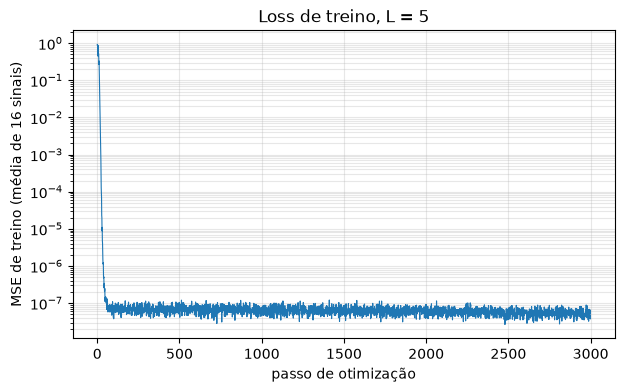

In [6]:
# 4.5: curva de loss em escala log
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(loss_history, linewidth=0.8)
ax.set_yscale("log")
ax.set_xlabel("passo de otimização")
ax.set_ylabel("MSE de treino (média de 16 sinais)")
ax.set_title("Loss de treino, L = 5")
ax.grid(True, which="both", alpha=0.3)
plt.show()

## 5. Avaliação e interpretação — 0,90 ponto

MSE de teste em 256 sequências novas. A acurácia de alinhamento é só um diagnóstico depois do treino.

In [7]:
@torch.no_grad()
def evaluate_fixed_length(n_sequences=256):
    # 5.1: A calculada uma vez
    Q = positions @ W_Q
    K = positions @ W_K
    A = compute_attention_weights(Q, K, logit_scale=logit_scale.exp())

    # 5.2: MSE média em sinais novos
    mses = []
    for _ in range(n_sequences):
        x = torch.randn(L, 1)
        mses.append(F.mse_loss(A @ x, torch.flip(x, dims=[0])))
    mean_mse = torch.stack(mses).mean().item()

    # 5.3: argmax de cada linha contra [L-1, ..., 0]
    expected = torch.arange(L - 1, -1, -1)
    alignment_accuracy = (A.argmax(dim=-1) == expected).float().mean().item()
    return mean_mse, alignment_accuracy, A


test_mse, alignment_accuracy, A = evaluate_fixed_length()
print(f"MSE de teste: {test_mse:.3e}")
print(f"Acurácia de alinhamento: {alignment_accuracy:.0%}")

MSE de teste: 5.637e-08
Acurácia de alinhamento: 100%


In [8]:
# Diagnóstico pós-treino: comparação com a matriz de inversão R (não usada no treino)
R = torch.flip(torch.eye(L), dims=[0])
print(
    "argmax por linha:",
    A.argmax(dim=-1).tolist(),
    "| esperado:",
    list(range(L - 1, -1, -1)),
)
print(
    "peso na posição certa (anti-diagonal):", [f"{w:.8f}" for w in A[R.bool()].tolist()]
)
print(
    "massa fora da anti-diagonal por linha:",
    [f"{m:.2e}" for m in (A * (1 - R)).sum(dim=-1).tolist()],
)
print("maior peso fora da anti-diagonal:", f"{A[~R.bool()].max().item():.2e}")

argmax por linha: [4, 3, 2, 1, 0] | esperado: [4, 3, 2, 1, 0]
peso na posição certa (anti-diagonal): ['0.99973983', '0.99982506', '0.99977499', '0.99988353', '0.99986553']
massa fora da anti-diagonal por linha: ['2.60e-04', '1.75e-04', '2.25e-04', '1.16e-04', '1.35e-04']
maior peso fora da anti-diagonal: 1.31e-04


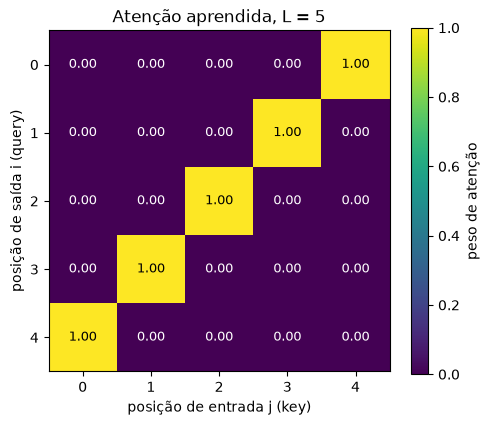

In [9]:
# 5.4: heatmap de A com valores entre 0 e 1
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(A.numpy(), vmin=0, vmax=1, cmap="viridis")
for i in range(L):
    for j in range(L):
        ax.text(
            j,
            i,
            f"{A[i, j]:.2f}",
            ha="center",
            va="center",
            color="black" if A[i, j] > 0.5 else "white",
            fontsize=9,
        )
ax.set_xticks(range(L))
ax.set_yticks(range(L))
ax.set_xlabel("posição de entrada j (key)")
ax.set_ylabel("posição de saída i (query)")
ax.set_title(f"Atenção aprendida, L = {L}")
fig.colorbar(im, ax=ax, label="peso de atenção")
plt.show()

### Resposta escrita 5

**Perguntas**

1. Por que um padrão de atenção anti-diagonal inverte a sequência?
2. O maior peso de cada linha seleciona a posição de entrada esperada?
3. A acurácia de alinhamento pode ser 100% com a MSE ainda acima de zero? Explique.
4. Por que o modelo treinado não pode ser aplicado diretamente a `L=8`?

**Respostas**

1. **Anti-diagonal é a matriz de inversão.** A saída é $\hat y_i=\sum_j A_{ij}x_j$, uma média ponderada dos valores
   da entrada. Se a linha $i$ tem peso 1 em $j=L-1-i$ e 0 no resto, então $\hat y_i=x_{L-1-i}$. Essa $A$ é a matriz
   de permutação $R_L$ (a identidade com as linhas na ordem inversa), e $R_Lx=\operatorname{reverse}(x)$. O heatmap
   mostra exatamente isso: 1,00 na anti-diagonal e 0,00 no resto.

2. **Sim.** O argmax das linhas foi `[4, 3, 2, 1, 0]`, igual ao esperado, com alinhamento de 100%. O treino nunca viu
   esse padrão como alvo. Ele surgiu porque a anti-diagonal é a única matriz estocástica que zera o erro de saída para
   qualquer $x$.

3. **Sim, e foi o que aconteceu.** O alinhamento é 100% e a MSE de teste é $5{,}6\times10^{-8}$, pequena mas positiva.
   Com logits finitos, o softmax dá peso estritamente positivo a todas as posições, então $A$ nunca é exatamente $R_L$:
   o peso na anti-diagonal ficou entre 0,99974 e 0,99988, e sobrou uma massa de $1{,}2$ a $2{,}6\times10^{-4}$ por linha
   espalhada nas outras posições. Essa massa mistura um pouco dos outros valores em cada saída, e é daí que vem a MSE.
   O argmax só exige que o peso certo seja o maior. A MSE zero exigiria peso exatamente 1, o que pediria logits
   infinitos. Os zeros que aparecem nas tabelas das Partes III e IV (em $L=4$) não contradizem isso: o peso fora do
   lugar fica tão pequeno que some no arredondamento do `float32`.

4. **Porque os parâmetros são indexados por posição absoluta.** $W_Q,W_K\in\mathbb R^{5\times8}$ têm uma linha por
   posição de $I_5$. Para $L=8$ o produto $I_8W_Q$ não existe, as posições 5 a 7 não têm parâmetros, e os pares
   aprendidos (0↔4, 1↔3, …) não são os pares certos para $L=8$ (0↔7, 1↔6, …). O modelo memorizou uma permutação
   específica em vez da regra de espelhamento ("a saída $i$ lê a entrada $L-1-i$"), que muda com $L$. A Parte III
   resolve isso com features de posição de dimensão fixa, normalizadas pelo comprimento.

## Fontes e uso de IA

- Slides da disciplina: *Transformers 2 — Attention Mechanism*, *Transformers 3 — Multi-head* e *Transformers 4 — Transformer* (Prof. Eric A. Antonelo).
- A. Zhang, Z. C. Lipton, M. Li e A. J. Smola, *Dive into Deep Learning*, cap. 11 (Attention Mechanisms and Transformers), d2l.ai.
- Documentação do PyTorch (`torch.softmax`, `Tensor.masked_fill`, `torch.nn.functional.mse_loss`, `torch.optim.Adam`).
- Assistência de IA: Claude Code (Anthropic), usado na implementação. Executei e conferi todos os resultados.

## Checklist final

- [x] A loss usa só a sequência prevista e a sequência alvo.
- [x] Cada atualização faz a média de 16 sinais aleatórios.
- [x] A MSE de teste usa 256 sinais novos.
- [x] O heatmap de atenção e a análise escrita estão visíveis.